# Projekt - konwergencja gospodarcza - ujęcie globalne

1. Pozyskaj dane dotyczące PKB per capita dla maksymalnej liczby gospodarek z bazy WB. Wykorzystaj szereg czasowy: *GDP per capita, PPP (constant 2021 international dollars)*, pomiń w analizie agregatowe grupy państw (np. grupa państw subsaharyjskich, grupa państw UE) znajdujące się w bazie WB.


In [47]:
%pip install world_bank_data
import pandas as pd
import world_bank_data  as wb
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

countries = wb.get_countries()

real_countries = countries[countries['region'] != 'Aggregates']
country_codes = real_countries.index.tolist()

print(f"Liczba wybranych krajów (bez agregatów): {len(country_codes)}")


indicator = "NY.GDP.PCAP.PP.KD"
df = wb.get_series(indicator, country=country_codes)


df = df.reset_index()
df.columns = ["Kraj", "Wskaznik", "Rok", "PKB_per_capita"]

df["PKB_per_capita"] = pd.to_numeric(
    df["PKB_per_capita"], errors="coerce"
)

df["Rok"] = df["Rok"].astype(str)


df = df.dropna(subset=["Kraj", "Rok", "PKB_per_capita"])
df = df[df["PKB_per_capita"] > 0].copy()

print("Dataset dimensions:", df.shape)
print("Duplicate country-year records:",
      df.duplicated(["Kraj", "Rok"]).sum())
print("Missing values:\n", df.isna().sum())
print("Available period:",
      df["Rok"].min(), "-", df["Rok"].max())

df.to_csv("gdp_per_capita_ppp.csv", index=False)


Liczba wybranych krajów (bez agregatów): 217
Dataset dimensions: (6977, 4)
Duplicate country-year records: 0
Missing values:
 Kraj              0
Wskaznik          0
Rok               0
PKB_per_capita    0
dtype: int64
Available period: 1990 - 2025


2. Zlogarytmuj uzyskane szeregi (log naturalny). Oblicz ich średnią wartość dla kolejnych lat dla wszystkich państw i przedstaw na wykresie liniowym.

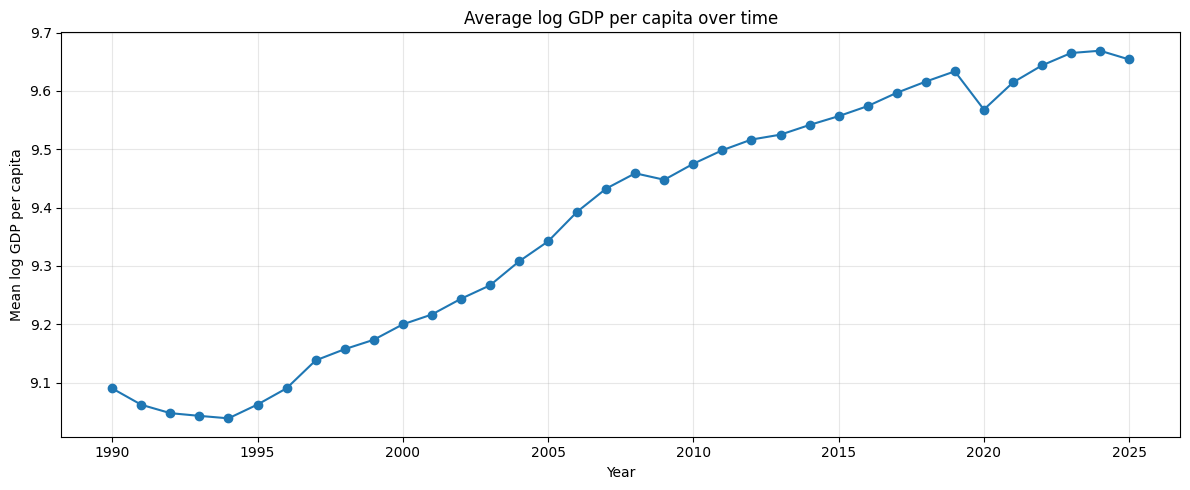

In [48]:

df["Log_PKB"] = np.log(df["PKB_per_capita"])

mean_log_gdp = (
    df.groupby("Rok")["Log_PKB"]
    .mean()
    .reset_index()
)

mean_log_gdp["Rok"] = mean_log_gdp["Rok"].astype(int)
mean_log_gdp = mean_log_gdp.sort_values("Rok")

plt.figure(figsize=(12, 5))
plt.plot(
    mean_log_gdp["Rok"],
    mean_log_gdp["Log_PKB"],
    marker="o"
)

plt.title("Average log GDP per capita over time")
plt.xlabel("Year")
plt.ylabel("Mean log GDP per capita")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


3. Konwergencja typu σ. Oblicz wariancję log PKB per capita we wszystkich gospodarkach w latach 1990 oraz 2022. Oceń, czy istnieje statystyczna różnica pomiędzy wariancjami log PKB per capita w tych latach. TIP. Odpowiedz na pytanie, o czym świadczy ten wynik.





In [49]:
start_year = "1990"
end_year = "2021"
years_span = int(end_year) - int(start_year)


y_start = df[df["Rok"] == start_year].set_index("Kraj")["Log_PKB"]
y_end = df[df["Rok"] == end_year].set_index("Kraj")["Log_PKB"]

beta_data = pd.concat(
    [y_start.rename("y_start"), y_end.rename("y_end")],
    axis=1
).dropna()

beta_data["g"] = (beta_data["y_end"] - beta_data["y_start"]) / years_span


X = sm.add_constant(beta_data["y_start"])
model = sm.OLS(beta_data["g"], X).fit(cov_type="HC3")

print(model.summary())
print("-" * 50)

n_countries = len(beta_data)
beta_coef = model.params["y_start"]
p_val = model.pvalues["y_start"]
ci_beta = model.conf_int().loc["y_start"]

print(f"Number of countries: {n_countries}")
print(f"Beta coefficient (slope): {beta_coef:.4f}")
print(f"P-value: {p_val:.4f}")
print(f"95% confidence interval: [{ci_beta[0]:.4f}, {ci_beta[1]:.4f}]")
print("-" * 50)

if beta_coef < 0 and p_val < 0.05:
    print(" Conclusion: Beta coefficient is negative and statistically significant.")
    print("  Evidence of BETA-CONVERGENCE (catch-up effect):")
    print(f"   Countries that started with lower GDP in {start_year} grew significantly faster,")
    print("   meaning poorer economies were catching up with richer ones.")
elif beta_coef > 0 and p_val < 0.05:
    print(" Conclusion: Beta coefficient is positive and statistically significant.")
    print("   Evidence of DIVERGENCE:")
    print("   Richer countries grew faster on average, widening the economic gap.")
else:
    print(f" Conclusion: The coefficient is not statistically significant (p = {p_val:.4f} > 0.05).")
    print("   No statistically significant evidence of beta-convergence or divergence over this period.")

                            OLS Regression Results                            
Dep. Variable:                      g   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.085
Method:                 Least Squares   F-statistic:                     12.80
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           0.000445
Time:                        14:19:56   Log-Likelihood:                 505.90
No. Observations:                 185   AIC:                            -1008.
Df Residuals:                     183   BIC:                            -1001.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0545      0.011      4.850      0.0

4. Konwergencja typu β. Dla każdego kraju oblicz log PKB per capita w roku 1990 (*y*) oraz średnie stopy wzrostu PKB per capita dla lat 1990-2021 (*g*).


In [58]:

y = df[df['Rok'] == '1990'].set_index('Kraj')['PKB_per_capita'].apply(np.log).dropna()
pkb_2021 = df[df['Rok'] == '2021'].set_index('Kraj')['PKB_per_capita'].apply(np.log).dropna()
g = (pkb_2021 - y) / (2021 - 1990)

g = g.dropna()
y = y.loc[g.index]

slope, intercept, r_value, p_value, std_err = stats.linregress(y, g)

print(f"Koeficijent beta (nachylenie): {slope:.4f}")
print(f"P-value: {p_value:.4f}")

if slope < 0 and p_value < 0.05:
    print("\n[CONCLUSION]: There is β-convergence (poorer countries do indeed grow faster than wealthier ones; the effect is confirmed).")

elif slope < 0 and p_value >= 0.05:
    print("\n[CONCLUSION]: There is no evidence of convergence (while a certain trend appears to exist, the difference is so small that it could simply be a coincidence).")

elif slope > 0 and p_value < 0.05:
    print("\n[CONCLUSION]: Divergence is occurring (the rich are growing faster than the poor; the gap between countries is only widening).")

else:
    print("\n[CONCLUSION]: No evidence of any relationship (growth rate does not depend on initial wealth).")

Koeficijent beta (nachylenie): -0.0042
P-value: 0.0000

[CONCLUSION]: There is β-convergence (poorer countries do indeed grow faster than wealthier ones; the effect is confirmed).



5. Na wykresie punktowym (*scatterplot*) przedstaw uzyskane wartości dla wszystkich państw łącznie (*y* na osi odciętych, *g* na osi rzędnych).


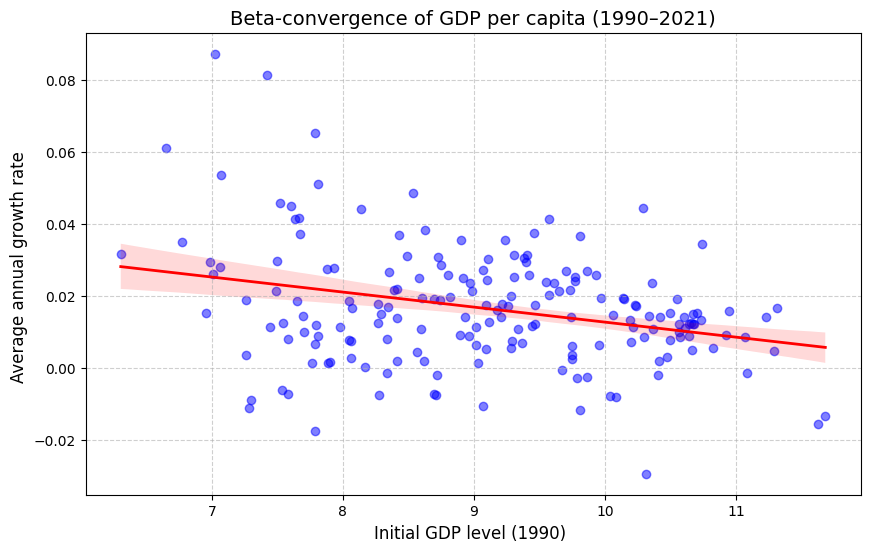

In [59]:

plt.figure(figsize=(10, 6))

sns.regplot(
    x=y,
    y=g,
    scatter_kws={'alpha': 0.5, 'color': 'blue'},
    line_kws={'color': 'red', 'linewidth': 2},
    ci=90,
    color='gray'
)

plt.title('Beta-convergence of GDP per capita (1990–2021)', fontsize=14)
plt.xlabel('Initial GDP level (1990) ', fontsize=12)
plt.ylabel('Average annual growth rate ', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


6. Kowergencja typu β - podejście 2. Oblicz różnice pomiędzy log PKB per capita każdego z krajów a log PKB per capita dla USA w latach 1990 i 2022. Stwórz histogram pokazujący rozkład zmiennych dla obu lat.

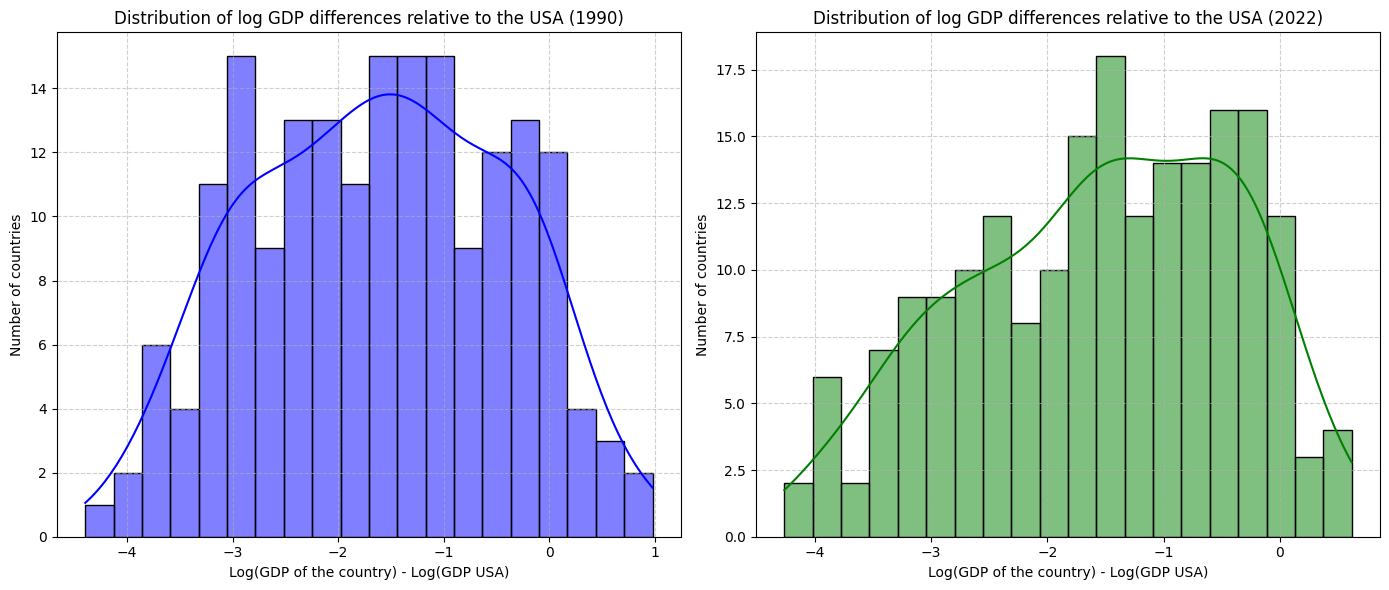

In [68]:

us_1990 = df[(df['Kraj'] == 'United States') & (df['Rok'] == '1990')]['Log_PKB'].values[0]
us_end = df[(df['Kraj'] == 'United States') & (df['Rok'] == '2022')]['Log_PKB'].values[0]

df_1990 = df[df['Rok'] == '1990'].copy()
df_1990['Diff_US'] = df_1990['Log_PKB'] - us_1990

df_end = df[df['Rok'] == '2022'].copy()
df_end['Diff_US'] = df_end['Log_PKB'] - us_end
plt.figure(figsize=(14, 6))


plt.subplot(1, 2, 1)
sns.histplot(df_1990['Diff_US'], kde=True, color='blue', bins=20)
plt.title('Distribution of log GDP differences relative to the USA (1990)', fontsize=12)
plt.xlabel('Log(GDP of the country) - Log(GDP USA)', fontsize=10)
plt.ylabel('Number of countries', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)


plt.subplot(1, 2, 2)
sns.histplot(df_end['Diff_US'], kde=True, color='green', bins=20)
plt.title('Distribution of log GDP differences relative to the USA (2022)', fontsize=12)
plt.xlabel('Log(GDP of the country) - Log(GDP USA)', fontsize=10)
plt.ylabel('Number of countries', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("konwergencja_us_histograms.png")
plt.show()

7. Dla obu podokresów zakwalifikuj każdy kraj do jednej z trzech grup:
* *high* - jeśli kraj cechuje się PKB per capita powyżej 75. percentyle rozkładu dystansu PKB per capita względem USA dla wszystkich gospodarek znajdujących się w próbie,
* *middle* - jeśli kraj cechuje się PKB per capita pomiędzy 25. and 75. (włącznie) percentylem rozkładu dystansu PKB per capita względem USA dla wszystkich gospodarek znajdujących się w próbie,
* *low* - jeśli kraj cechuje się PKB per capita poniżej 25% PKB per capita w USA.

  TIP. Wykorzystaj do tego celu zmienne 0/1, np. uzyskane za pomocą funkcji *where* z biblioteki Numpy.


In [61]:

p25_1990 = df_1990['Diff_US'].quantile(0.25)
p75_1990 = df_1990['Diff_US'].quantile(0.75)


df_1990['Group'] = np.where(
    df_1990['Diff_US'] > p75_1990, 'high',
    np.where(df_1990['Diff_US'] >= p25_1990, 'middle', 'low')
)

p25_end = df_end['Diff_US'].quantile(0.25)
p75_end = df_end['Diff_US'].quantile(0.75)

df_end['Group'] = np.where(
    df_end['Diff_US'] > p75_end, 'high',
    np.where(df_end['Diff_US'] >= p25_end, 'middle', 'low')
)

print("Grupy w 1990 roku:")
print(df_1990['Group'].value_counts())

print("\nGrupy w 2022 roku:")
print(df_end['Group'].value_counts())

Grupy w 1990 roku:
Group
middle    93
high      46
low       46
Name: count, dtype: int64

Grupy w 2022 roku:
Group
middle    99
low       50
high      50
Name: count, dtype: int64


8.  Na podstawie przeprowadzonej powyżej klasyfikacji stwórz zmienne opisujące "przejście" pomiędzy grupami (lub jego brak) dla każdego kraju pomiędzy latami 1990 i 2022. Rozważ wszystkie możliwe kombinacje, a więc: *high* - *high*, *middle* - *high*, *low* - *middle*, itd. (w sumie 9 klas). Dodatkowo stwórz dwie kategorie:
* *upgrade* - jeśli kraj przeszedł z niższej do wyższej klasy,
* *downgrade* - jeśli spadł z wyższej do niższej klasy.


In [62]:
df_transition = pd.merge(
    df_1990[['Kraj', 'Group']],
    df_end[['Kraj', 'Group']],
    on='Kraj',
    suffixes=('_1990', '_end')
)

print("1990 rok:")
print(df_1990['Group'].value_counts())

print("\n2022 rok:")
print(df_end['Group'].value_counts())

df_transition['Przejście'] = df_transition['Group_1990'] + ' -> ' + df_transition['Group_end']

rank_map = {'low': 1, 'middle': 2, 'high': 3}

r1990 = df_transition['Group_1990'].str.lower().map(rank_map)
rend = df_transition['Group_end'].str.lower().map(rank_map)
df_transition['Wynik'] = np.where(
    rend > r1990, 'upgrade',
    np.where(rend < r1990, 'downgrade', 'stable')
)

print(df_transition[['Kraj', 'Przejście', 'Wynik']])

1990 rok:
Group
middle    93
high      46
low       46
Name: count, dtype: int64

2022 rok:
Group
middle    99
low       50
high      50
Name: count, dtype: int64
                     Kraj         Przejście      Wynik
0                   Aruba    high -> middle  downgrade
1                  Angola  middle -> middle     stable
2                 Albania  middle -> middle     stable
3                 Andorra      high -> high     stable
4    United Arab Emirates      high -> high     stable
..                    ...               ...        ...
180               Vanuatu     middle -> low  downgrade
181                 Samoa  middle -> middle     stable
182          South Africa  middle -> middle     stable
183                Zambia        low -> low     stable
184              Zimbabwe     middle -> low  downgrade

[185 rows x 3 columns]


9. Stwórz tabelę podsumowującą liczbę oraz udział procentowy krajów we wszystkich 11 kategoriach wyróżnionych w punkcie (8). Zinterpretuj uzyskane wyniki. Sporządź listę krajów, które zmieniły swoje położenie w ramach przyjętej klasyfikacji.


In [70]:
counts = df_transition['Przejście'].value_counts()
percentages = df_transition['Przejście'].value_counts(normalize=True) * 100

summary_table = pd.DataFrame({
    'Number of countries': counts,
    'Share (%)': percentages.round(2)
})

print("---Transition table---")
print(summary_table)

changed_countries = df_transition[df_transition['Wynik'] != 'stable']

print("\n--- Countries that have changed their location ---")
print(changed_countries[['Kraj', 'Przejście', 'Wynik']])

---Transition table---
                  Number of countries  Share (%)
Przejście                                       
middle -> middle                   76      41.08
high -> high                       39      21.08
low -> low                         35      18.92
middle -> low                      11       5.95
low -> middle                      11       5.95
high -> middle                      7       3.78
middle -> high                      6       3.24

--- Countries that have changed their location ---
                       Kraj       Przejście      Wynik
0                     Aruba  high -> middle  downgrade
15               Bangladesh   low -> middle    upgrade
18             Bahamas, The  high -> middle  downgrade
19   Bosnia and Herzegovina   low -> middle    upgrade
33                    China   low -> middle    upgrade
35                 Cameroon   middle -> low  downgrade
37              Congo, Rep.   middle -> low  downgrade
40               Cabo Verde   low -> middle 

10. Przedstaw otrzymane wyniki na wykresie punktowym, na którym za pomocą przerywanych linii zaznacz odpowiednie klasy "przejścia" krajów wyróżnione w punkcie (8).


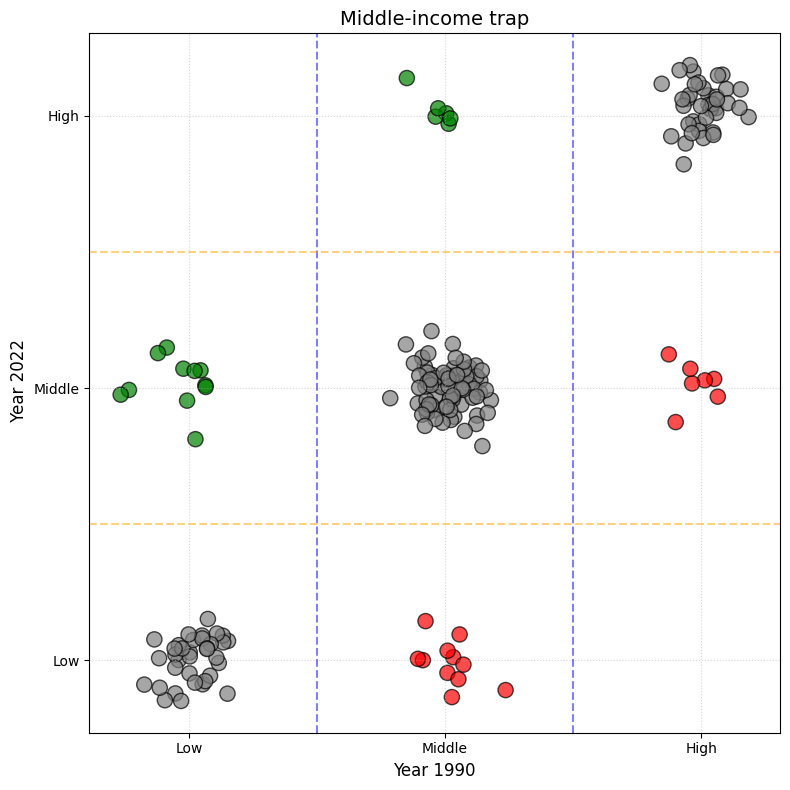

In [72]:
plt.figure(figsize=(8, 8))

jitter_x = np.random.normal(0, 0.08, size=len(df_transition))
jitter_y = np.random.normal(0, 0.08, size=len(df_transition))

rank_map = {'low': 1, 'middle': 2, 'high': 3}
x_vals = df_transition['Group_1990'].map(rank_map) + jitter_x
y_vals = df_transition['Group_end'].map(rank_map) + jitter_y

plt.scatter(
    x_vals, y_vals,
    c=df_transition['Wynik'].map({'upgrade': 'green', 'downgrade': 'red', 'stable': 'gray'}),
    s=120, alpha=0.7, edgecolors='k'
)

plt.axvline(x=1.5, color='blue', linestyle='--', alpha=0.5, label='Межі класів')
plt.axvline(x=2.5, color='blue', linestyle='--', alpha=0.5)
plt.axhline(y=1.5, color='orange', linestyle='--', alpha=0.5)
plt.axhline(y=2.5, color='orange', linestyle='--', alpha=0.5)

plt.xticks([1, 2, 3], ['Low', 'Middle', 'High'])
plt.yticks([1, 2, 3], ['Low', 'Middle', 'High'])

plt.title('Middle-income trap', fontsize=14)
plt.xlabel('Year 1990', fontsize=12)
plt.ylabel(' Year 2022', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()